# Fuzzy logic

The aim of this notebook is to present fuzzy sets, fuzzy inference and defuzzification by building
a fuzzy controller of the kind the assignment requires.

In [1]:
!pip install plotly --quiet

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "figure.figsize": (7.0, 4.0),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "legend.fontsize": 10,
})
pio.templates.default = "plotly_white"
pio.renderers.default = "colab"

In [2]:
#@title Plot helpers: 2D { display-mode: "form" }
def interp(universe, membership, x):
    """Membership of a single value, read off a sampled membership function."""
    return float(np.interp(x, universe, membership))

def plot_curves(ax, series, xlabel="", ylabel="", title="", ylim=None):
    """series: {label: (x, y)}. One line each."""
    for label, (xs, ys) in series.items():
        ax.plot(xs, ys, lw=2.5, label=label)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if ylim:
        ax.set_ylim(*ylim)
    if len(series) > 1:
        ax.legend(fontsize=9)

def plot_memberships(ax, universe, sets, value=None, xlabel="", title=""):
    """Every membership function of one variable, optionally marking an input."""
    for name, mf in sets.items():
        label = name if value is None else f"{name}  (mu = {interp(universe, mf, value):.2f})"
        ax.plot(universe, mf, lw=2.5, label=label)
    if value is not None:
        ax.axvline(value, color="black", lw=2, ls="--")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$\mu$")
    ax.set_ylim(-0.05, 1.15)
    ax.set_title(title)
    ax.legend(fontsize=9)

def plot_descriptors(ax, x, membership, alpha):
    """Support and core as bands, plus the alpha-cut as a horizontal cut."""
    support = x[membership > 0]
    core = x[np.isclose(membership, 1.0)]
    cut = x[membership >= alpha]
    ax.plot(x, membership, lw=3, color="black", label=r"$\mu_A$")
    ax.axhline(alpha, color="tab:orange", ls="--", lw=1.5, label=rf"$\alpha = {alpha}$")
    ax.axvspan(support.min(), support.max(), color="tab:blue", alpha=0.12, label="support")
    ax.axvspan(core.min(), core.max(), color="tab:green", alpha=0.30, label="core")
    ax.plot(cut, np.full_like(cut, alpha), lw=5, color="tab:orange", label=r"$\alpha$-cut")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\mu_A(x)$")
    ax.set_title("Descriptors of a fuzzy set")
    ax.legend(fontsize=8, loc="upper left")

def plot_consequents(ax, universe, sets, strengths, aggregate, v_star, title="", show_full=()):
    """Clipped consequents, their aggregate, and the defuzzified value."""
    for name in show_full:
        ax.plot(universe, sets[name], lw=1.6, ls="--", color="grey", label=f"{name} (full set)")
    for name, w in strengths.items():
        ax.plot(universe, np.minimum(w, sets[name]), lw=2, label=f"{name} clipped at w = {w:.2f}")
    ax.fill_between(universe, aggregate, color="tab:purple", alpha=0.25, label="aggregate (max)")
    ax.axvline(v_star, color="tab:red", lw=2.5, label=f"centre of gravity = {v_star:+.2f}")
    ax.set_xlabel("velocity [px/frame]")
    ax.set_ylabel(r"$\mu(v)$")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper center")

In [3]:
#@title Plot helpers: 3D surfaces (interactive) and schematics { display-mode: "form" }
def show_surfaces(panels, height=430, zlim=None, color_range=None, colorscale="Viridis",
                  contours=False, corners=False, zticks=None, aspectratio=None, cols=None):
    """panels: [(X, Y, Z, title, zlabel), ...] drawn as interactive 3D surfaces.

    X and Y may be the 2D meshgrids themselves. `color_range` lets the colour
    scale follow the data while `zlim` may stay wider. `cols` fixes the grid
    width; by default two panels share a row.
    """
    cols = cols or (2 if len(panels) > 1 else 1)
    rows = int(np.ceil(len(panels) / cols))
    fig = make_subplots(rows=rows, cols=cols, specs=[[{"type": "surface"}] * cols] * rows,
                        subplot_titles=[panel[3] for panel in panels],
                        horizontal_spacing=0.03, vertical_spacing=0.06)
    low, high = color_range or zlim
    camera = dict(eye=dict(x=1.55, y=1.55, z=0.85))
    scenes = {}
    for index, (X, Y, Z, title, zlabel) in enumerate(panels, start=1):
        row, col = divmod(index - 1, cols)
        fig.add_trace(go.Surface(
            x=X, y=Y, z=Z, colorscale=colorscale, cmin=low, cmax=high, showscale=False,
            contours=dict(z=dict(show=True, usecolormap=True, width=2, project=dict(z=True)))
            if contours else None,
        ), row=row + 1, col=col + 1)
        if corners:
            marks = np.ix_([0, -1], [0, -1])          # the four {0,1} x {0,1} corners
            fig.add_trace(go.Scatter3d(
                x=X[marks].ravel(), y=Y[marks].ravel(), z=Z[marks].ravel(), mode="markers",
                marker=dict(size=4, color="black"), hoverinfo="skip", showlegend=False,
            ), row=row + 1, col=col + 1)
        scenes["scene" if index == 1 else f"scene{index}"] = dict(
            camera=camera,
            aspectmode="manual" if aspectratio else "cube",
            aspectratio=aspectratio,
            xaxis=dict(title="a" if corners else "dx [px]",
                       range=[0, 1] if corners else [-100, 100],
                       tickvals=[0, 0.5, 1] if corners else [-100, 0, 100]),
            yaxis=dict(title="b" if corners else "dy [px]",
                       range=[0, 1] if corners else [0, 150],
                       tickvals=[0, 0.5, 1] if corners else [0, 75, 150]),
            zaxis=dict(title=zlabel, range=list(zlim) if zlim else None, tickvals=zticks),
        )
    fig.update_layout(**scenes, height=height, margin=dict(l=0, r=0, t=40, b=0))
    fig.update_annotations(font=dict(size=15))
    fig.show()

def draw_pong_geometry():
    """The paddle, the ball, the collision window and the 25% booster band.

    Geometry read off the provided Pong.py: the paddle is 80 px wide, the ball is
    20 px on a side, and both paddles move at most 10 px per frame.
    """
    paddle_w, ball_size = 80, 20
    collision = (paddle_w + ball_size) // 2   # 50: inside this the ball touches the paddle
    power = (paddle_w - ball_size) // 2       # 30: outside this we hit with the edge

    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.axvspan(-collision, collision, color="tab:green", alpha=0.10)
    ax.axvspan(power, collision, color="tab:red", alpha=0.30)
    ax.axvspan(-collision, -power, color="tab:red", alpha=0.30)
    ax.add_patch(plt.Rectangle((-paddle_w / 2, -6), paddle_w, 12, color="steelblue",
                               label="paddle (80 px)"))
    ax.add_patch(plt.Rectangle((-ball_size / 2, 30), ball_size, ball_size, color="orange",
                               label="ball (20 px)"))
    ax.axvline(0, color="grey", lw=1, ls=":")
    ax.annotate("centre: deflect only", xy=(0, -18), ha="center", fontsize=10, color="tab:green")
    ax.annotate("outer 25%:\n+10% ball speed", xy=(-62, 62), ha="center", fontsize=10,
                color="tab:red")
    ax.annotate("outer 25%:\n+10% ball speed", xy=(62, 62), ha="center", fontsize=10,
                color="tab:red")
    ax.annotate("collision window: |dx| < 50", xy=(0, 96), ha="center", fontsize=10,
                color="dimgrey")
    ax.set_xlim(-105, 105)
    ax.set_ylim(-30, 114)
    ax.set_yticks([])
    ax.grid(False)
    ax.xaxis.grid(True, alpha=0.3)
    ax.set_xlabel("dx = paddle centre - ball centre  [px]")
    ax.set_title("What the controller is actually aiming at")
    ax.legend(loc="lower right", fontsize=9)
    plt.show()
    plt.close("all")

def draw_inference_chain():
    """The inference chain: five computational stages and the resulting command.

    The top row is shared by both methods. Stage 4 is where Mamdani and TSK part
    company, and both branches end in the same single number.
    """
    fig, ax = plt.subplots(figsize=(11, 4.4))
    ax.set_axis_off()
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    def box(cx, cy, w, h, text, color):
        ax.add_patch(plt.Rectangle((cx - w / 2, cy - h / 2), w, h, facecolor=color, alpha=0.13,
                                   edgecolor=color, lw=1.6))
        ax.text(cx, cy, text, ha="center", va="center", fontsize=11)

    def arrow(x0, y0, x1, y1):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="->", color="dimgrey", lw=1.6))

    box(0.13, 0.80, 0.24, 0.20, "crisp inputs\n$dx$, $dy$", "tab:blue")
    box(0.50, 0.80, 0.28, 0.20, "fuzzification\nmemberships $\\mu$", "tab:blue")
    box(0.87, 0.80, 0.24, 0.20, "rules\nfiring strengths $w$", "tab:blue")
    box(0.28, 0.46, 0.36, 0.22, "Mamdani: consequent is a set\nclip at $w$, aggregate with max",
        "tab:orange")
    box(0.73, 0.46, 0.42, 0.22, "TSK: consequent is a function\nevaluate $-k_i\\,dx$, average",
        "tab:green")
    box(0.50, 0.13, 0.46, 0.20, "crisp output\nvelocity $v$, $|v| \\leq 10$ px/frame", "tab:red")

    arrow(0.25, 0.80, 0.36, 0.80)
    arrow(0.64, 0.80, 0.75, 0.80)
    arrow(0.82, 0.70, 0.42, 0.57)
    arrow(0.90, 0.70, 0.80, 0.57)
    arrow(0.30, 0.35, 0.42, 0.23)
    arrow(0.72, 0.35, 0.58, 0.23)
    plt.show()
    plt.close("all")

---

## The inference chain

The controller receives two crisp numbers, `dx` and `dy`, and must return one crisp number, the
velocity of the paddle. There is no formula for that number. What is available is a description of
the behaviour in words: if the ball is to the left and near, move the paddle fast to the left. The
purpose of fuzzy inference is to convert such descriptions into arithmetic.

The conversion has six stages:

1. **Fuzzification.** Each crisp input is compared with the membership functions of its linguistic
   terms, which gives one membership per term: `dx` is `left` to degree 0.50 and `centre` to degree
   0.33.
2. **Rule firing.** Every rule of the rule table is evaluated. Its firing strength `w` is the degree
   to which its antecedent is satisfied, computed with a T-norm over the memberships from stage 1.
3. **Implication.** The firing strength is transferred to the consequent of the rule.
4. **Aggregation.** The consequents of all rules that fired are combined into a single
   representation of the output.
5. **Defuzzification.** That representation is collapsed to one crisp number.
6. **The command.** The number is the commanded velocity, which is applied to the paddle and is
   bounded by the paddle's speed limit.

Stages 1 and 2 are common to both inference methods used below. The methods differ from stage 3
onwards, that is, in what a consequent is and in how it is turned back into a number:

- **Mamdani**: the consequent is a fuzzy set, stage 3 cuts it down to `w`, and stage 5 computes the
  centre of gravity of the combined shape.
- **TSK**: the consequent is a function of the input, stage 3 evaluates it, and stage 5 takes the
  weighted average over the rules that fired.

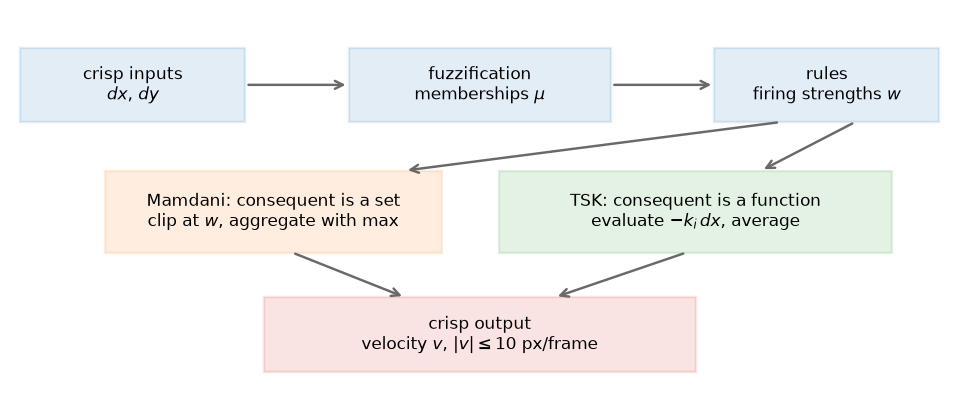

In [4]:
draw_inference_chain()

---

## Glossary

- **Universe of discourse** - the range of values a variable can take, for example `dx` from -100 to
  100 px. Membership functions are defined on it.
- **Linguistic variable** - a variable described by words rather than by numbers. `dx` is a
  linguistic variable, and the words are its terms.
- **Linguistic term** (a fuzzy set) - one of those words together with the membership function that
  defines it, for example `left` on the universe of `dx`.
- **Crisp value** - an ordinary number, for example dx = 20 px.
- **Membership function** $\mu_A(x)$ - gives, for each value of the universe, the degree to which it
  belongs to a term, between 0 and 1.
- **Fuzzification** - reading the memberships of a crisp value from the membership functions of a
  variable.
- **Support, core, alpha-cut, height** - descriptors of a fuzzy set: the values with membership above
  0, with membership equal to 1, with membership at least alpha, and the largest membership reached.
  A set of height 1 is *normalized*.
- **Rule** - an implication of the form `IF dx is left AND dy is near THEN v is fast_left`. The part
  before THEN is the *antecedent*, the part after is the *consequent*.
- **Rule base** - the set of rules, that is, the table that maps antecedent terms to consequent
  terms.
- **T-norm and S-norm** - the fuzzy counterparts of AND and OR, used to combine memberships into one
  antecedent degree. `min` and `max` are the Zadeh pair.
- **Firing strength** $w$ - the membership of the antecedent of a rule for the current inputs.
- **Implication** - transferring a firing strength to the consequent. In Mamdani it cuts the
  consequent set down to $w$.
- **Aggregation** - combining the consequents of the rules that fired into one representation of the
  output.
- **Inference** - stages 1 to 5 together, from crisp inputs to a fuzzy output.
- **Defuzzification** - collapsing a fuzzy output into one crisp number. The centre of gravity is the
  common choice.
- **Mamdani method** - fuzzy consequents; implication by clipping, aggregation by `max`,
  defuzzification by centre of gravity.
- **TSK method** - consequents are functions of the input; the output is their $w$-weighted average.
- **Control surface** - the commanded velocity as a function of `dx` and `dy`, that is, the behaviour
  of the controller over the whole input space.

---

## Fuzzy sets and membership functions

A fuzzy set $A$ on a universe $X$ is defined by its **membership function**
$\mu_A : X \to [0,1]$, where $\mu_A(x)$ says how much $x$ belongs to $A$. Zadeh proposed this in
1965.

Note the distinction: **uncertainty** is not knowing a fact (a coin not yet flipped, which
probability describes), while **imprecision** is a vague predicate that cannot be sharpened by
measurement ("tall"). Fuzzy sets model the second one.

Triangles and trapezia are the usual shapes; gaussians are also used, being continuous and
differentiable. The first two are used here.

height   crisp 'tall'   fuzzy mu
  170 cm        0          0.33
  175 cm        1          0.67
  180 cm        1          1.00
  190 cm        1          1.00
  205 cm        1          1.00


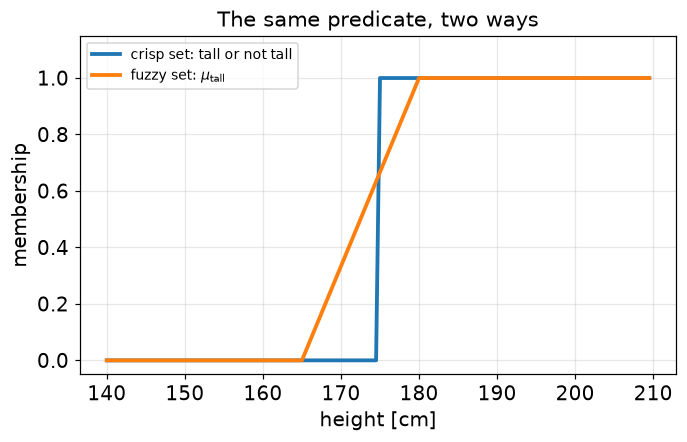

In [6]:
def tri(x, a, b, c):
    """Triangle: 0 at a, 1 at b, 0 at c."""
    return np.clip(np.minimum((x - a) / (b - a), (c - x) / (c - b)), 0.0, 1.0)

def trap(x, a, b, c, d):
    """Trapezoid: 0 at a, 1 between b and c, 0 at d."""
    return np.clip(np.minimum((x - a) / (b - a), (d - x) / (d - c)), 0.0, 1.0)

def build_mf(universe, shape):
    """Build a membership function from a ("tri" | "trap", parameters) pair."""
    kind, params = shape
    return tri(universe, *params) if kind == "tri" else trap(universe, *params)

HEIGHTS = np.arange(140, 210, 0.5)          # cm
TALL = trap(HEIGHTS, 165, 180, 220, 260)    # plateau past the end of the universe: a shoulder

# A membership function returns a degree, not a verdict
print("height   crisp 'tall'   fuzzy mu")
for h in (170.0, 175.0, 180.0, 190.0, 205.0):
    print(f"{h:5.0f} cm        {int(h >= 175)}          {interp(HEIGHTS, TALL, h):.2f}")

fig, ax = plt.subplots()
plot_curves(ax, {
    "crisp set: tall or not tall": (HEIGHTS, (HEIGHTS >= 175).astype(float)),
    r"fuzzy set: $\mu_{\mathrm{tall}}$": (HEIGHTS, TALL),
}, xlabel="height [cm]", ylabel="membership", title="The same predicate, two ways", ylim=(-0.05, 1.15))
plt.show()
plt.close("all")

A membership function describes one term of one variable. A variable normally carries several
terms at once, and the shape of each follows the same rule: a term that only ever gains evidence
saturates at the end of the universe, while a term that applies over an interval is bounded on
both sides. A thermostat, with room temperature as the input, uses both kinds.

temp [C]   cold   medium   hot   total
  10     1.00    0.00   0.00   1.00
  17     1.00    0.00   0.00   1.00
  19     0.50    0.50   0.00   1.00
  21     0.00    1.00   0.00   1.00
  23     0.00    0.50   0.50   1.00
  25     0.00    0.00   1.00   1.00
  30     0.00    0.00   1.00   1.00


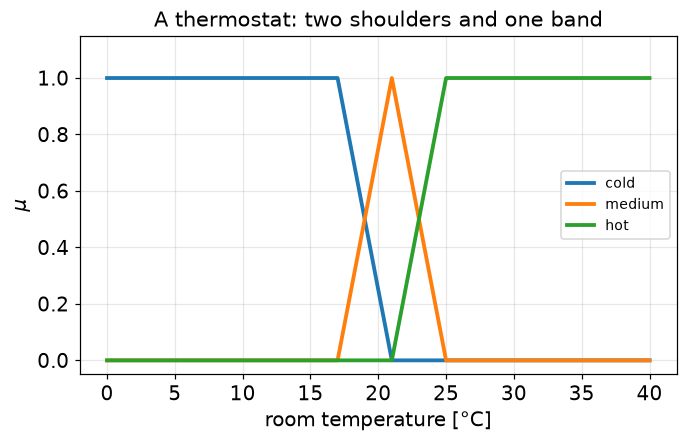

In [7]:
TEMP = np.arange(0, 40.001, 0.05)           # °C
TEMP_SHAPE = {
    "cold":   ("trap", (-6, 0, 17, 21)),    # shoulder: 1 up to 17, 0 at 21
    "medium": ("tri", (17, 21, 25)),        # band: 0 at 17, 1 at 21, 0 at 25
    "hot":    ("trap", (21, 25, 40, 44)),   # shoulder: 0 at 21, 1 from 25
}
temp_sets = {name: build_mf(TEMP, shape) for name, shape in TEMP_SHAPE.items()}

print("temp [C]   cold   medium   hot   total")
for t in (10, 17, 19, 21, 23, 25, 30):
    mu = [interp(TEMP, mf, t) for mf in temp_sets.values()]
    print(f"{t:4d}     {mu[0]:.2f}    {mu[1]:.2f}   {mu[2]:.2f}   {sum(mu):.2f}")

fig, ax = plt.subplots()
plot_memberships(ax, TEMP, temp_sets, xlabel="room temperature [°C]",
                 title="A thermostat: two shoulders and one band")
plt.show()
plt.close("all")

---

## Describing a fuzzy set

Four descriptors, defined from the membership function:

- **height** $h(A) = \sup_x \mu_A(x)$ - if $h(A) = 1$ the set is said to be *normalized*
- **support** $= \{x : \mu_A(x) > 0\}$ - everything that belongs even a little
- **core** $= \{x : \mu_A(x) = 1\}$ - everything that fully belongs
- **alpha-cut** $A_\alpha = \{x : \mu_A(x) \geq \alpha\}$ - the set at confidence level $\alpha$

height(A) = 1.00  -> normalized (height 1)
support(A) = [2.05, 8.95]   (mu > 0)
core(A)    = [4.00, 6.00]   (mu = 1)
0.4-cut(A)   = [2.80, 7.75]   (mu >= 0.4)


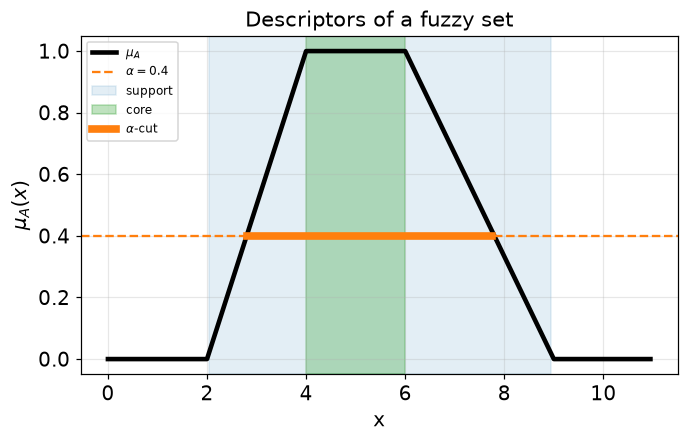

In [8]:
x = np.arange(0, 11, 0.05)
A = trap(x, 2, 4, 6, 9)                 # some asymmetric fuzzy set
ALPHA = 0.4

support = x[A > 0]
core = x[np.isclose(A, 1.0)]
alpha_cut = x[A >= ALPHA]
print(f"height(A) = {A.max():.2f}  -> "
      f"{'normalized (height 1)' if A.max() == 1 else 'not normalized'}")
print(f"support(A) = [{support.min():.2f}, {support.max():.2f}]   (mu > 0)")
print(f"core(A)    = [{core.min():.2f}, {core.max():.2f}]   (mu = 1)")
print(f"{ALPHA}-cut(A)   = [{alpha_cut.min():.2f}, {alpha_cut.max():.2f}]   (mu >= {ALPHA})")

fig, ax = plt.subplots()
plot_descriptors(ax, x, A, ALPHA)
plt.show()
plt.close("all")

## Operators: T-norms and S-norms

In crisp logic, AND is defined by a truth table of four rows: `0 AND 0 = 0`, `0 AND 1 = 0`,
`1 AND 0 = 0`, and `1 AND 1 = 1`. If we treat the two inputs and the output as coordinates
$(a, b, \text{result})$ inside a unit cube $[0, 1]^3$, these four rows pin four of the cube's
eight vertices: three at height 0 and one at height 1. The crisp OR table pins $(0, 0, 0)$ and
$(1, 1, 1)$ as well, but raises the two mixed corners $(0, 1)$ and $(1, 0)$ to height 1.

In fuzzy logic, memberships take continuous values in $[0, 1]$, turning the operator from four
isolated points into a continuous **surface (a sheet)** spanning the cube. While infinitely
many surfaces could interpolate the four crisp corners, fuzzy logic requires operators to satisfy
four core mathematical axioms:
1. **Boundary condition:** must match crisp logic at the extremes (e.g., $a \text{ AND } 1 = a$).
2. **Monotonicity:** increasing an input membership must never decrease the result.
3. **Commutativity:** $A \text{ AND } B \equiv B \text{ AND } A$ (the surface is symmetric across the diagonal).
4. **Associativity:** $(A \text{ AND } B) \text{ AND } C \equiv A \text{ AND } (B \text{ AND } C)$,
   which allows chaining multi-premise rules consistently.

Operators satisfying these axioms for conjunction (AND) are called **T-norms**. Their dual
counterparts for disjunction (OR) are called **S-norms** (or **T-conorms**).

Two standard families are compared below:
* The **Zadeh pair** ($\min$ for AND, $\max$ for OR) folds the surface sharply along the diagonal
  $a = b$. The result is governed strictly by the bottleneck (the weaker premise for AND, the
  stronger for OR). Importantly, Zadeh operators are **idempotent** ($\min(a, a) = a$), meaning
  repeating the same premise does not dilute or amplify the belief.
* The **algebraic pair** (the product $a \cdot b$ for AND, the probabilistic sum $a + b - ab$ for OR)
  bends the surface smoothly. It penalizes partial truth more strictly (e.g., $0.5 \text{ AND } 0.5$
  yields $0.25$, whereas $\min$ retains $0.50$). Crucially, the algebraic operators are **smooth and
  differentiable everywhere**, which is indispensable for gradient-based neuro-fuzzy systems (such as ANFIS).

In [9]:
GRID = np.linspace(0.0, 1.0, 101)
A2, B2 = np.meshgrid(GRID, GRID, indexing="ij")

def zadeh_and(a, b):
    return np.minimum(a, b)

def algebraic_and(a, b):
    return a * b

def zadeh_or(a, b):
    return np.maximum(a, b)

corners = np.array([0.0, 1.0])
ca, cb = np.meshgrid(corners, corners, indexing="ij")
print("where the families disagree:")
print(f"  on the crisp corners {{0,1}} : max |min(a,b) - a*b| = "
      f"{np.abs(zadeh_and(ca, cb) - algebraic_and(ca, cb)).max():.2f}")
print(f"  over the unit square      : max |min(a,b) - a*b| = "
      f"{np.abs(zadeh_and(A2, B2) - algebraic_and(A2, B2)).max():.2f}")
print("  -> identical truth tables, different behaviour at partial truth")

show_surfaces([
    (A2, B2, zadeh_and(A2, B2), "Zadeh AND: min(a, b)", "AND(a, b)"),
    (A2, B2, algebraic_and(A2, B2), "algebraic AND: a · b", "AND(a, b)"),
    (A2, B2, zadeh_or(A2, B2), "Zadeh OR: max(a, b)", "OR(a, b)"),
], zlim=(0, 1), zticks=[0, 0.5, 1], corners=True, cols=3, height=480)

where the families disagree:
  on the crisp corners {0,1} : max |min(a,b) - a*b| = 0.00
  over the unit square      : max |min(a,b) - a*b| = 0.25
  -> identical truth tables, different behaviour at partial truth


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

The four marked points are the corners that the crisp tables pin, and all three panels pass through
them. The first panel folds along the diagonal $a = b$: on one side the height is $a$ and does not
change with $b$, on the other it is $b$. The product panel is smooth where the first one folds, and
lies below it, by at most 0.25, at the centre of the square. The third panel is the first with `max`
in place of `min`.

---

## Fuzzification and firing strength

A rule has the form `IF dx is left AND dy is near THEN v is fast_left`. **Fuzzification** takes
crisp inputs and returns the antecedent memberships. The **firing strength** $w$ of the rule is the
degree to which its antecedent is satisfied. With the Zadeh AND of the previous section that degree
is the smaller of the premise memberships, so the rule holds as strongly as its least satisfied
premise, no more and no less. Both operators are applied to the same input below.

The two inputs are the two values available to the Pong controller: the horizontal and the vertical
distance between the centres of the ball and the paddle.

inputs: dx = -20 px   dy = 30 px

  dx is left   -> mu = 0.50
  dx is centre -> mu = 0.33
  dx is right  -> mu = 0.00
  dy is near   -> mu = 0.83
  dy is far    -> mu = 0.00

rule 'IF dx is left AND dy is near' at dx = -20 px, dy = 30 px:
  Zadeh AND     w = min(0.50, 0.83) = 0.50
  algebraic AND w = 0.50 * 0.83    = 0.42


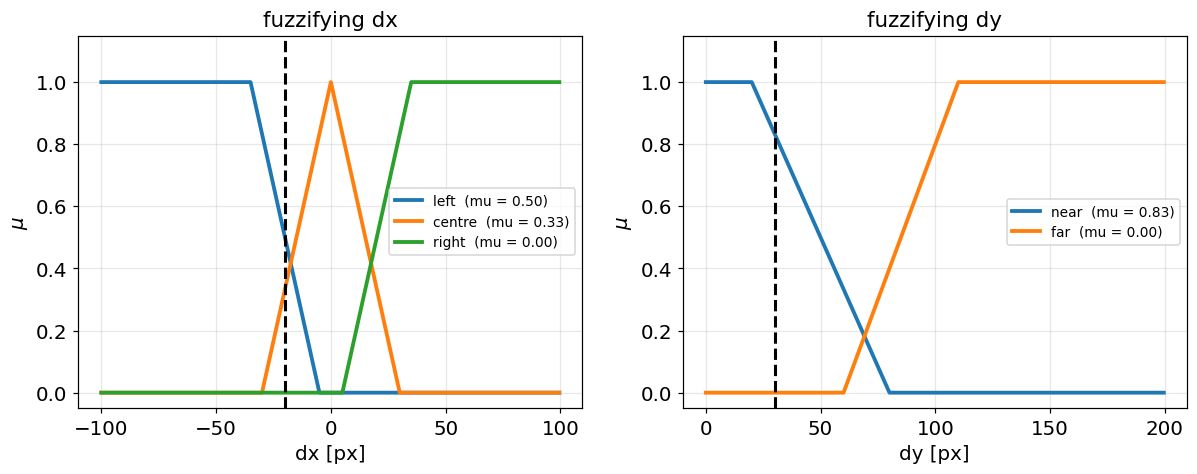

In [ ]:
DX = np.arange(-100, 100, 0.5)      # dx = ball centre - paddle centre, px (negative = left, positive = right)
DY = np.arange(0, 200, 0.5)         # dy = vertical distance, px (never negative in this game)

# Shapes kept separate from the sampled arrays so scikit-fuzzy can reuse them later
DX_SHAPE = {
    "left":   ("trap", (-160, -100, -35, -5)),
    "centre": ("tri",  (-30, 0, 30)),
    "right":  ("trap", (5, 35, 100, 160)),
}
DY_SHAPE = {
    "near": ("trap", (-60, -20, 20, 80)),
    "far":  ("trap", (60, 110, 220, 280)),
}

dx_sets = {name: build_mf(DX, shape) for name, shape in DX_SHAPE.items()}
dy_sets = {name: build_mf(DY, shape) for name, shape in DY_SHAPE.items()}

DX_INPUT, DY_INPUT = -20.0, 30.0   # one instant of the game, reused throughout: ball 20px to the LEFT

mu_x = {name: interp(DX, mf, DX_INPUT) for name, mf in dx_sets.items()}
mu_y = {name: interp(DY, mf, DY_INPUT) for name, mf in dy_sets.items()}
print(f"inputs: dx = {DX_INPUT:.0f} px   dy = {DY_INPUT:.0f} px\n")
for name, value in mu_x.items():
    print(f"  dx is {name:6s} -> mu = {value:.2f}")
for name, value in mu_y.items():
    print(f"  dy is {name:6s} -> mu = {value:.2f}")

w_zadeh = zadeh_and(mu_x["left"], mu_y["near"])
w_algebraic = algebraic_and(mu_x["left"], mu_y["near"])
print(f"\nrule 'IF dx is left AND dy is near' at dx = {DX_INPUT:.0f} px, dy = {DY_INPUT:.0f} px:")
print(f"  Zadeh AND     w = min({mu_x['left']:.2f}, {mu_y['near']:.2f}) = {w_zadeh:.2f}")
print(f"  algebraic AND w = {mu_x['left']:.2f} * {mu_y['near']:.2f}    = {w_algebraic:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_memberships(axes[0], DX, dx_sets, DX_INPUT, "dx [px]", "fuzzifying dx")
plot_memberships(axes[1], DY, dy_sets, DY_INPUT, "dy [px]", "fuzzifying dy")
plt.show()
plt.close("all")

### The output variable: commanded velocity

The controller commands a single crisp number, the paddle velocity $v \in [-10, 10]$ px/frame. Negative values move the paddle to the left, positive values to the right, and values near zero keep it stationary.

Five linguistic terms partition the universe: `fast_left`, `slow_left`, `stop`, `slow_right`, and `fast_right`.

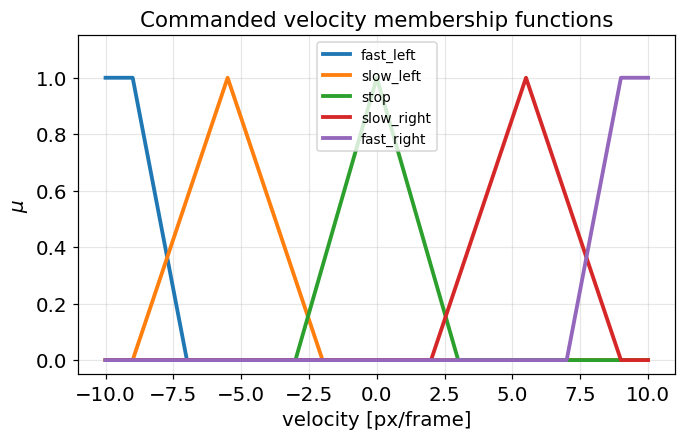

In [ ]:
V = np.arange(-10, 10.01, 0.01)  # commanded velocity, px/frame

V_SHAPE = {
    "fast_left":  ("trap", (-11, -10, -9, -7)),
    "slow_left":  ("tri",  (-9, -5.5, -2)),
    "stop":       ("tri",  (-3, 0, 3)),
    "slow_right": ("tri",  (2, 5.5, 9)),
    "fast_right": ("trap", (7, 9, 10, 11)),
}
v_sets = {name: build_mf(V, shape) for name, shape in V_SHAPE.items()}

fig, ax = plt.subplots()
plot_memberships(ax, V, v_sets, xlabel="velocity [px/frame]",
                 title="Commanded velocity membership functions")
plt.show()
plt.close("all")

### The rule base

A rule connects antecedent terms to a consequent term. For a basic ball-following controller, six rules relate the three horizontal terms and two vertical terms to commanded velocity:

* IF dx is left AND dy is near THEN v is fast_left
* IF dx is left AND dy is far THEN v is slow_left
* IF dx is centre AND dy is near THEN v is stop
* IF dx is centre AND dy is far THEN v is stop
* IF dx is right AND dy is near THEN v is fast_right
* IF dx is right AND dy is far THEN v is slow_right

In [ ]:
RULE_TABLE = {
    ("left", "near"):    "fast_left",
    ("left", "far"):     "slow_left",
    ("centre", "near"):  "stop",
    ("centre", "far"):   "stop",
    ("right", "near"):   "fast_right",
    ("right", "far"):    "slow_right",
}

### Mamdani inference: clip, aggregate, centre of gravity

In the Mamdani model the consequent is a fuzzy set rather than a function, so inference yields a shape over the output universe. Three steps turn that shape back into a number:

1. **Implication**: each fired rule cuts its consequent set down to its firing strength $w$ using `min`. A rule asserts its consequent only as strongly as its premise holds, capping the set at that height.
2. **Aggregation**: all clipped consequents are combined into a single shape with a fuzzy OR (`max`).
3. **Defuzzification**: the combined shape is collapsed to a single number, usually the **centre of gravity**:
   $$\bar{v} = \frac{\int v \mu(v) \, dv}{\int \mu(v) \, dv}$$

To isolate how implication and defuzzification operate on an individual set, we first evaluate what the strongest rule from our table (`left AND near -> fast_left`) produces on its own when $w = 0.50$.

this rule on its own yields -8.74 px/frame


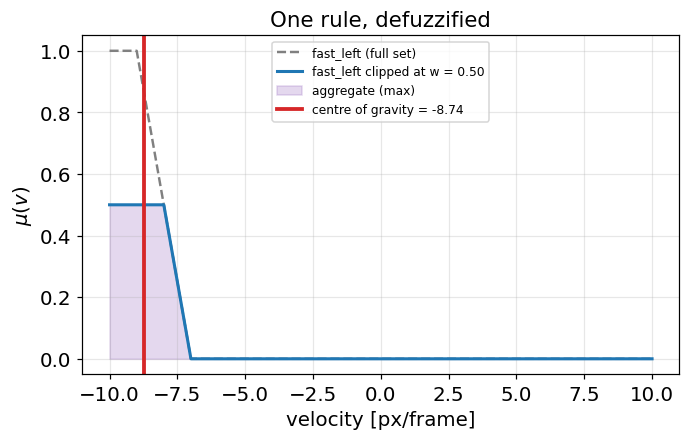

In [ ]:
def centroid(universe, membership):
    """Centre of gravity. Uniformly spaced samples cancel the step in both integrals."""
    total = membership.sum()
    return 0.0 if total <= 0 else float((universe * membership).sum() / total)

def aggregate(universe, sets, strengths):
    """Combine consequents that fire together with a fuzzy OR (max)."""
    out = np.zeros_like(universe)
    for name, w in strengths.items():
        out = np.maximum(out, np.minimum(w, sets[name]))
    return out

# The ('left', 'near') -> 'fast_left' rule fired with w = min(0.50, 0.83) = 0.50
W = 0.50
one_rule = aggregate(V, v_sets, {"fast_left": W})
v_one = centroid(V, one_rule)
print(f"this rule on its own yields {v_one:+.2f} px/frame")

fig, ax = plt.subplots()
plot_consequents(ax, V, v_sets, {"fast_left": W}, one_rule, v_one,
                 title="One rule, defuzzified", show_full=("fast_left",))
plt.show()
plt.close("all")

### Multi-rule inference and aggregation

In practice multiple rules can fire simultaneously. At our test point ($dx = -20$ px, $dy = 30$ px):
* `dx is left` has membership 0.50 and `dy is near` has membership 0.83, firing `fast_left` with $w = \min(0.50, 0.83) = 0.50$.
* `dx is centre` has membership 0.33 and `dy is near` has membership 0.83, firing `stop` with $w = \min(0.33, 0.83) = 0.33$.

The remaining four rules in the table evaluate to $w = 0$. Both active shapes are clipped, combined using `max`, and defuzzified together.

rules firing at dx = 20 px, dy = 30 px:
  IF dx is left   AND dy is near -> v is fast_left  w = 0.50
  IF dx is centre AND dy is near -> v is stop       w = 0.33

aggregate commands -3.75 px/frame


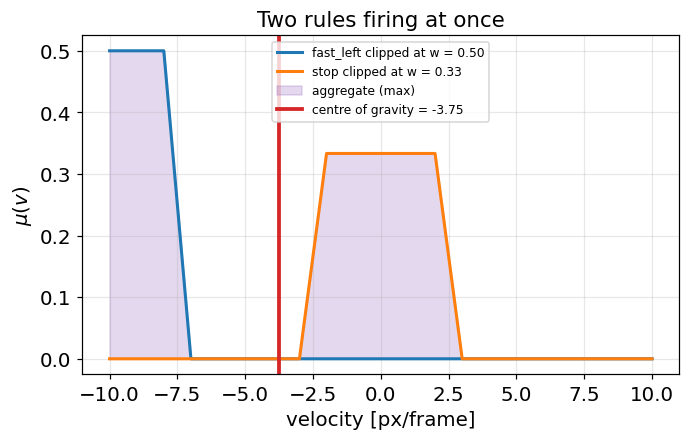

In [ ]:
def firing_strengths(dx, dy):
    """Fuzzify both inputs and take the min for every rule in the table."""
    mu_x = {name: interp(DX, mf, dx) for name, mf in dx_sets.items()}
    mu_y = {name: interp(DY, mf, dy) for name, mf in dy_sets.items()}
    return {(x, y): min(mu_x[x], mu_y[y]) for x, y in RULE_TABLE}

def consequent_strengths(dx, dy):
    """Keep the strongest rule per consequent term: rules with the same consequent are aggregated."""
    out = {}
    for (x, y), w in firing_strengths(dx, dy).items():
        term = RULE_TABLE[x, y]
        out[term] = max(out.get(term, 0.0), w)
    return out

def mamdani_velocity(dx, dy):
    """The whole chain: fuzzify -> fire -> clip -> aggregate -> defuzzify."""
    strengths = {term: w for term, w in consequent_strengths(dx, dy).items() if w > 0}
    if not strengths:
        return 0.0
    return centroid(V, aggregate(V, v_sets, strengths))

print("rules firing at dx = 20 px, dy = 30 px:")
for (x_term, y_term), w in firing_strengths(DX_INPUT, DY_INPUT).items():
    if w > 0:
        print(f"  IF dx is {x_term:6s} AND dy is {y_term:4s} -> v is {RULE_TABLE[x_term, y_term]:10s} w = {w:.2f}")

v_cmd = mamdani_velocity(DX_INPUT, DY_INPUT)
print(f"\naggregate commands {v_cmd:+.2f} px/frame")

fired = {t: w for t, w in consequent_strengths(DX_INPUT, DY_INPUT).items() if w > 0}
fig, ax = plt.subplots()
plot_consequents(ax, V, v_sets, fired, aggregate(V, v_sets, fired),
                 v_cmd, title="Two rules firing at once")
plt.show()
plt.close("all")

When `fast_left` fired alone, it commanded $-8.74$ px/frame. With both rules firing, the combined centre of gravity shifts to $-3.75$ px/frame.

This illustrates a property of the method: the centre of gravity is an area-weighted average. The `stop` triangle is wide (base width 6), so even at a lower firing strength of 0.33 it contributes substantial area to the aggregate shape. This pulls the balance point strongly towards zero. The behaviour is adjusted through the rule table or through the shape of the consequent, not through the defuzzifier.

In [ ]:
!pip install scikit-fuzzy --quiet

Commanded velocity: -3.74 px/frame


/home/ludovic/Documents/Projets/AI/Pong/.venv/lib/python3.14/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


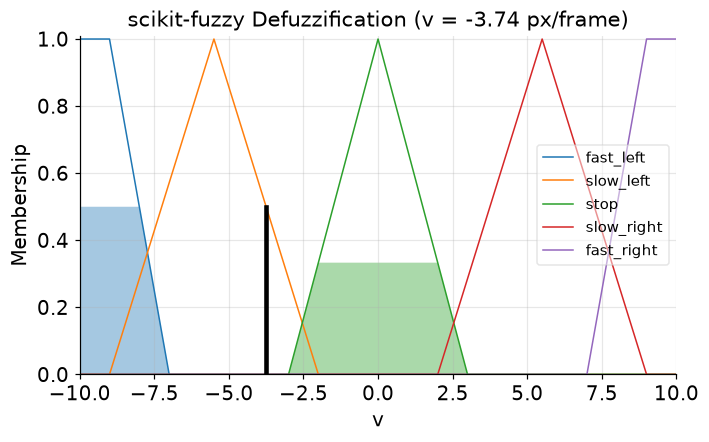

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# =============================================================================
# 1. DEFINE UNIVERSES OF DISCOURSE & FUZZY VARIABLES
# =============================================================================
# Universes: the range of crisp values each variable can take
dx_universe = np.arange(-100, 100.5, 0.5)  # horizontal distance (px)
dy_universe = np.arange(0, 200.5, 0.5)     # vertical distance (px)
v_universe  = np.arange(-10, 10.01, 0.01)  # paddle velocity (px/frame)

# ctrl.Antecedent -> Input variable
# ctrl.Consequent -> Output variable (defaults to centroid/center-of-gravity defuzzification)
dx = ctrl.Antecedent(dx_universe, 'dx')
dy = ctrl.Antecedent(dy_universe, 'dy')
v  = ctrl.Consequent(v_universe,  'v')


# =============================================================================
# 2. DEFINE MEMBERSHIP FUNCTIONS (LINGUISTIC TERMS)
# =============================================================================
# fuzz.trimf  -> triangular:  [start, peak, end]
# fuzz.trapmf -> trapezoidal: [start, plateau_start, plateau_end, end]

# Input 1: dx (positive = ball is to the left of the paddle)
dx['right']  = fuzz.trapmf(dx.universe, [-160, -100, -35, -5])
dx['centre'] = fuzz.trimf(dx.universe,  [-30, 0, 30])
dx['left']   = fuzz.trapmf(dx.universe, [5, 35, 100, 160])

# Input 2: dy (vertical distance to incoming ball)
dy['near']   = fuzz.trapmf(dy.universe, [-60, -20, 20, 80])
dy['far']    = fuzz.trapmf(dy.universe, [60, 110, 220, 280])

# Output: v (paddle velocity: negative = move left, positive = move right)
v['fast_left']  = fuzz.trapmf(v.universe, [-11, -10, -9, -7])
v['slow_left']  = fuzz.trimf(v.universe,  [-9, -5.5, -2])
v['stop']       = fuzz.trimf(v.universe,  [-3, 0, 3])
v['slow_right'] = fuzz.trimf(v.universe,  [2, 5.5, 9])
v['fast_right'] = fuzz.trapmf(v.universe, [7, 9, 10, 11])


# =============================================================================
# 3. DEFINE THE RULEBASE
# =============================================================================
# Connect antecedents to consequents using standard operators:
#   & -> AND (T-norm: min)
#   | -> OR  (S-norm: max)
#   ~ -> NOT (Negation: 1 - mu)
rule1 = ctrl.Rule(dx['left']   & dy['near'], v['fast_left'])
rule2 = ctrl.Rule(dx['left']   & dy['far'],  v['slow_left'])
rule3 = ctrl.Rule(dx['centre'] & dy['near'], v['stop'])
rule4 = ctrl.Rule(dx['centre'] & dy['far'],  v['stop'])
rule5 = ctrl.Rule(dx['right']  & dy['near'], v['fast_right'])
rule6 = ctrl.Rule(dx['right']  & dy['far'],  v['slow_right'])


# =============================================================================
# 4. BUILD THE SYSTEM & INSTANTIATE SIMULATION
# =============================================================================
# ControlSystem aggregates the rule base
pong_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6])

# ControlSystemSimulation executes inference for specific inputs
sim = ctrl.ControlSystemSimulation(pong_ctrl)


# =============================================================================
# 5. PASS CRISP INPUTS & PERFORM INFERENCE
# =============================================================================
# Test point: ball is 20 px to the left and 30 px away
sim.input['dx'] = 20.0
sim.input['dy'] = 30.0

# Compute: Fuzzify -> Evaluate Rules -> Implicate (Clip) -> Aggregate -> Defuzzify
sim.compute()

commanded_v = sim.output['v']
print(f"Commanded velocity: {commanded_v:+.2f} px/frame")


# =============================================================================
# 6. BUILT-IN VISUALIZATION
# =============================================================================
# Visualizes the clipped shapes and the centroid line directly
v.view(sim=sim)
plt.title(f"scikit-fuzzy Defuzzification (v = {commanded_v:+.2f} px/frame)")
plt.show()

### TSK: consequents as functions

In the Mamdani model, rule consequents are fuzzy sets, which requires numerical defuzzification (cutting shapes and computing the centre of gravity).

The **TSK (Takagi–Sugeno–Kang)** model is a general fuzzy inference architecture where rule consequents are **functions of the inputs** rather than fuzzy sets:
$$\text{IF } \mathbf{x} \text{ is } A_i \quad \text{THEN } y = f_i(\mathbf{x})$$

Because each rule directly evaluates to a crisp number, there are no shapes to clip, no output universe to discretise, and no defuzzification. The overall system output is simply the **weighted average** of all rule outputs:
$$\bar{y} = \frac{\sum_i w_i \cdot f_i(\mathbf{x})}{\sum_i w_i}$$
where $i$ indexes the rules in the rule base, and $w_i$ is the firing strength of rule $i$ computed from the antecedents via a T-norm (identical to Mamdani).

Depending on the form of $f_i(\mathbf{x})$, TSK systems fall into two categories:

1. **Zero-order TSK (constants):**
   Each rule outputs a fixed constant number, $f_i(\mathbf{x}) = c_i$. The final output is:
   $$\bar{y} = \frac{\sum_i w_i \cdot c_i}{\sum_i w_i}$$

2. **First-order TSK (linear functions):**
   Each rule outputs a linear function of the input variables:
   $$f_i(\mathbf{x}) = a_{i,1} x_1 + a_{i,2} x_2 + \dots + b_i$$

---

#### Applying TSK to our Pong paddle controller

To compare TSK directly with the Mamdani controller constructed above, we apply both variants to our running Pong example. Here the inputs are $\mathbf{x} = (dx, dy)$ and the commanded output $y$ is paddle velocity $v \in [-10, 10]$ px/frame. We reuse the exact same six rules and membership functions from our rule table.

* **In zero-order TSK**, each consequent term is mapped to a constant speed:
  * `fast_left` $\to -10$ px/frame
  * `stop` $\to 0$ px/frame
  * `fast_right` $\to +10$ px/frame

* **In first-order TSK**, each rule outputs a velocity proportional to horizontal distance:
  $$f_i(dx) = k_i \cdot dx$$
  where $k_i$ is the proportional gain of that rule:
  * `fast` rules use $k = 0.25$ (aggressive response)
  * `slow` rules use $k = 0.15$ (gentle response)
  * `stop` uses $k = 0.0$ (no motion)

  *(Notice that vertical distance $dy$ does not need to appear directly in $f_i(dx)$: it already does its job through the antecedent weights $w_i$, determining whether the controller blends in a `fast` or a `slow` rule).*

The commanded velocity is the weighted average across all rules that fired:
$$\bar{v} = \frac{\sum_i w_i \cdot (k_i \cdot dx)}{\sum_i w_i}$$

In [ ]:
# Multipliers per action (converts distance in px into speed in px/frame)
# Note: k = 0.25 means at dx = 40 px, velocity = 0.25 * 40 = 10 px/frame (max speed)
GAIN = {
    "fast_left":  0.25,  # Aggressive: reaches max speed at 40 px distance
    "slow_left":  0.15,  # Gentle: reaches max speed only at ~67 px distance
    "stop":       0.0,   # Stationary
    "slow_right": 0.15,
    "fast_right": 0.25,
}

def tsk_velocity(dx, dy):
    """
    Computes paddle velocity using First-Order TSK.
    Uses the same membership functions and rule table as Mamdani,
    but replaces fuzzy output shapes with linear formulas: velocity = k * dx.
    """
    numerator = 0.0    # sum of (weight * proposed_velocity)
    denominator = 0.0  # sum of (weights)

    # Loop over all rules in our table and their firing strengths w:
    for (x_term, y_term), w in firing_strengths(dx, dy).items():
        action = RULE_TABLE[x_term, y_term]  # e.g. 'fast_left'
        k = GAIN[action]                     # multiplier: e.g. 0.25

        # Linear consequent: what velocity does this rule want?
        proposal = k * dx

        # Accumulate the weighted vote:
        numerator += w * proposal
        denominator += w

    # Safety guard against division by zero (if no rules fired):
    if denominator <= 0:
        return 0.0

    # Weighted average: sum(w * proposal) / sum(w)
    # Clamp to paddle speed limit (-10 to +10 px/frame):
    return float(np.clip(numerator / denominator, -10.0, 10.0))

In [ ]:
# Print comparison across dx at our reference dy
print(" dx [px] | Mamdani [px/frame] | TSK [px/frame]")
print("---------+--------------------+----------------")
for test_dx in (-80, -40, -20, 0, 20, 40, 80):
    m_val = mamdani_velocity(float(test_dx), DY_INPUT)
    t_val = tsk_velocity(float(test_dx), DY_INPUT)
    print(f"  {test_dx:+4d}   |      {m_val:+7.2f}       |     {t_val:+7.2f}")

print("\nthe 'stop' rule still votes: it contributes 0 to the numerator but w to the denominator")

 dx [px] | Mamdani [px/frame] | TSK [px/frame]
---------+--------------------+----------------
   -80   |        -8.87       |      -10.00
   -40   |        -8.87       |      -10.00
   -20   |        -3.75       |       -3.00
    +0   |        +0.00       |       +0.00
   +20   |        +3.75       |       +3.00
   +40   |        +8.87       |      +10.00
   +80   |        +8.87       |      +10.00

the 'stop' rule still votes: it contributes 0 to the numerator but w to the denominator


At $dx = -20$ px the two methods differ: Mamdani commands $-3.75$ px/frame and TSK $-3.00$.

The evaluation for TSK at $dx = -20$ px and $dy = 30$ px breaks down into two active rules:
* `IF dx is left AND dy is near` fires with $w = 0.50$ and proposes $0.25 \cdot (-20) = -5.00$ px/frame.
* `IF dx is centre AND dy is near` fires with $w = 0.33$ and proposes $0.0 \cdot (-20) = 0.00$ px/frame.

The weighted average blends them:
$$\bar{v} = \frac{0.50 \cdot (-5.00) + 0.33 \cdot 0}{0.50 + 0.33} = \frac{-2.50}{0.83} = -3.00\text{ px/frame}$$

The damping comes from the `stop` rule. It proposes 0 motion, but its weight still enters the denominator, pulling the commanded velocity toward zero. In Mamdani the same damping is provided by the area of the `stop` triangle.

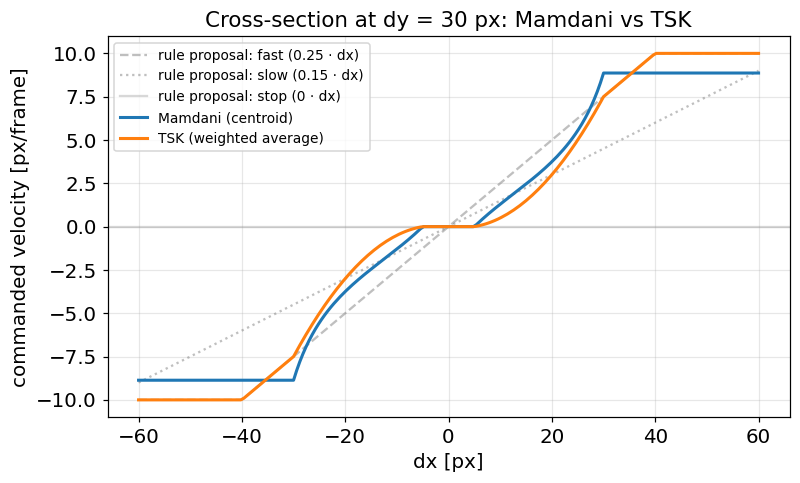

In [ ]:
# Cross-section along dx at fixed dy: showing how TSK blends local linear laws
slice_dx = np.linspace(-60, 60, 201)

mamdani_slice = [mamdani_velocity(x, DY_INPUT) for x in slice_dx]
tsk_slice     = [tsk_velocity(x, DY_INPUT) for x in slice_dx]

fig, ax = plt.subplots(figsize=(8, 4.5))

# Individual rule laws (proposals before weighting)
ax.plot(slice_dx, np.clip(0.25 * slice_dx, -10, 10), "--", color="gray", alpha=0.5, label="rule proposal: fast (0.25 · dx)")
ax.plot(slice_dx, np.clip(0.15 * slice_dx, -10, 10), ":", color="gray", alpha=0.5, label="rule proposal: slow (0.15 · dx)")
ax.axhline(0.0, color="gray", alpha=0.3, label="rule proposal: stop (0 · dx)")

# Controller outputs
ax.plot(slice_dx, mamdani_slice, label="Mamdani (centroid)", color="tab:blue", lw=2)
ax.plot(slice_dx, tsk_slice, label="TSK (weighted average)", color="tab:orange", lw=2)

ax.set_xlabel("dx [px]")
ax.set_ylabel("commanded velocity [px/frame]")
ax.set_title(f"Cross-section at dy = {DY_INPUT:.0f} px: Mamdani vs TSK")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="upper left")
plt.show()
plt.close("all")

The cross-section reveals what the weighted average does. Near $dx = 0$, the controller adheres to the horizontal `stop` line. As $|dx|$ grows, the weights smoothly transfer control to the steeper `fast` line. This is gain scheduling: the controller behaves like a collection of linear models stitched together by fuzzy logic.

In [ ]:
# Full control surfaces over the entire input space
SURF_DX = np.linspace(-100, 100, 41)
SURF_DY = np.linspace(0, 150, 31)
SURF_X, SURF_Y = np.meshgrid(SURF_DX, SURF_DY)

SURFACE_MAMDANI = np.array([[mamdani_velocity(float(x), float(y)) for x in SURF_DX] for y in SURF_DY])
SURFACE_TSK     = np.array([[tsk_velocity(float(x), float(y)) for x in SURF_DX] for y in SURF_DY])

show_surfaces([
    (SURF_X, SURF_Y, SURFACE_MAMDANI, "Mamdani: centre of gravity", "v [px/frame]"),
    (SURF_X, SURF_Y, SURFACE_TSK,     "TSK: weighted average",      "v [px/frame]"),
], height=520, zlim=(-13, 13), color_range=(-10, 10), zticks=[-10, 0, 10],
   colorscale="RdBu_r", contours=True, aspectratio=dict(x=1, y=1, z=0.45))

The two methods differ at each stage after rule firing:

* **consequent**: Mamdani uses a fuzzy set; TSK uses a function of the input.
* **implication**: Mamdani clips the set at $w$; TSK evaluates the function and weights it by $w$.
* **combination**: Mamdani aggregates with `max` and integrates for the centre of gravity; TSK computes a weighted average directly, so it has no defuzzification step.
* **output range**: a Mamdani output is bounded by the universe of its consequent; a TSK output is unbounded and must be clipped explicitly to the paddle's speed limit.
* **saturation**: on the surfaces, Mamdani saturates near $\pm 8.9$ px/frame and never reaches the paddle's limit of $\pm 10$, because the centre of gravity of a 2D shape over $[-10, 10]$ cannot reach the edge without having zero width. The TSK surface reaches $\pm 10$ and is clipped there.

### Back to the Pong task

The assignment requires implementing a fuzzy controller for the **player paddle** in `Pong.py` using `scikit-fuzzy`. The controller receives two inputs: the horizontal and vertical distances between the center of the ball and the center of the paddle ($dx, dy$), and must command both the speed and direction of the paddle ($v$).

The ball does not inherit the paddle's velocity. Instead, reflecting the ball using the **edgemost 25% of the paddle increases the ball's speed by 10%**. Because both paddles have a hard speed limit, repeatedly accelerating the ball with the edges will eventually cause it to outrun the opponent's paddle.

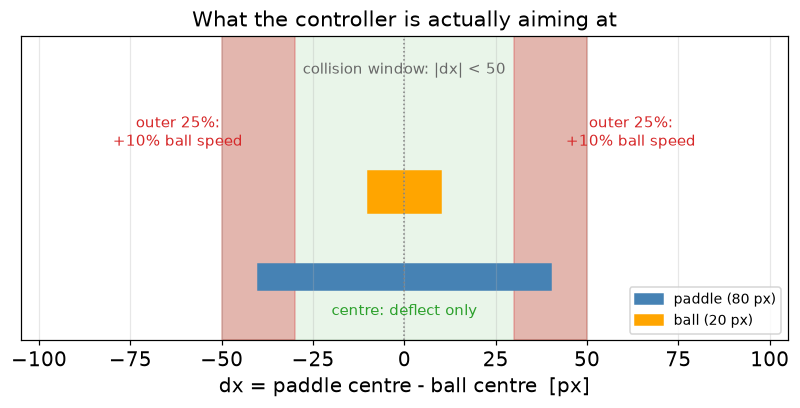

In [ ]:
draw_pong_geometry()

### Collision geometry and target zones

As shown in the diagram above:
* Paddle width is $80$ px (half-width $40$ px), and ball width is $20$ px (half-width $10$ px).
* A collision occurs whenever the ball touches any part of the paddle: **$|dx| \le 50$ px**. If $|dx| > 50$ px, the paddle misses.
* The edgemost 25% speed-boost zone lies between $20$ and $40$ px from the paddle center. Accounting for the ball's width, edge reflections occur in the window **$30 < |dx| \le 50$ px**.

---

### Assignment requirements and grading tiers

The controller built in this notebook serves as a reference implementation. To complete Task 4.1, structure your submission according to the grading targets:

* **Grade 3.0 (Mamdani ball-following):**
  Implement a Mamdani controller using `scikit-fuzzy` that tracks the ball's centre ($dx \approx 0$). The paddle must successfully deflect the ball and never let the opponent score under normal speeds.
* **Grade 4.0 (TSK ball-following):**
  Implement a TSK controller (constructed manually in NumPy, as demonstrated above) that performs the same ball-following task.
* **Grade 5.0 (Edge-reflection strategy):**
  Design an advanced rule base that actively attempts to intercept the ball using the outer edge ($30 < |dx| \le 50$ px). The rules must account for incoming ball trajectory to accelerate the ball until the naive opponent can no longer keep up, without risking a miss past $|dx| = 50$ px.

---

### Pre-submission checklist

Before submitting the archive:
1. **No zero-sum states:** Verify that your membership functions cover the entire input domain with sufficient overlap so that at least one rule always fires ($\sum \mu > 0$).
2. **Speed saturation:** Ensure the commanded velocity strictly respects the paddle's speed limit ($\pm 10$ px/frame) in both inference methods.
3. **Packaging:** Name your submission file exactly `{Task Number}_{ID}_{Name}_{Surname}.zip` (e.g. `4.1_123456_Jan_Kowalski.zip`) and include a working `requirements.txt` specifying package versions.